In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

设备: cuda
GPU: Tesla T4
y 的范围: 1.0025e+00 ~ 7.2213e+86
跨越了 86.9 个数量级


/tmp/ipykernel_3163/2250235891.py:25: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_3163/2250235891.py:25: UserWarning: Glyph 24615 (\N{CJK UNIFIED IDEOGRAPH-6027}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_3163/2250235891.py:25: UserWarning: Glyph 32437 (\N{CJK UNIFIED IDEOGRAPH-7EB5}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_3163/2250235891.py:25: UserWarning: Glyph 36724 (\N{CJK UNIFIED IDEOGRAPH-8F74}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_3163/2250235891.py:25: UserWarning: Glyph 23545 (\N{CJK UNIFIED IDEOGRAPH-5BF9}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_3163/2250235891.py:25: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3

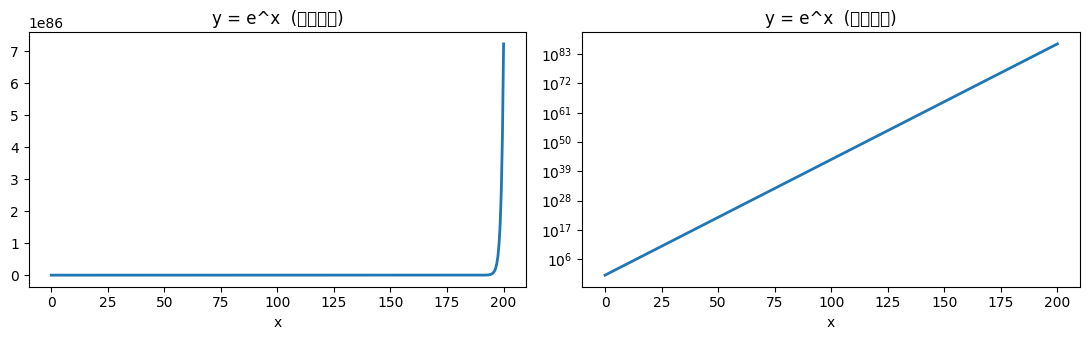

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("设备:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch.manual_seed(0)

# ---------- 造数据 ----------
N = 200_000
x = torch.rand(N, 1, dtype=torch.float64) * 200.0   # x ~ U(0, 200)
y = torch.exp(x)                                     # y = e^x

print(f"y 的范围: {y.min():.4e} ~ {y.max():.4e}")
print(f"跨越了 {torch.log10(y.max()/y.min()):.1f} 个数量级")

# 看一眼形状
xs = torch.linspace(0, 200, 400, dtype=torch.float64)
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(xs, torch.exp(xs), lw=2); plt.title("y = e^x  (线性纵轴)")
plt.xlabel("x")
plt.subplot(1, 2, 2)
plt.plot(xs, torch.exp(xs), lw=2); plt.yscale("log")
plt.title("y = e^x  (对数纵轴)"); plt.xlabel("x")
plt.tight_layout(); plt.show()

In [11]:
# 输入归一到 [-1, 1]；目标 = ln(y)/200 ∈ [0, 1]
u = (x / 100.0 - 1.0).float().to(device)
t = (x / 200.0).float().squeeze(-1).to(device)   # (N, 1) → (N,)

class MLP(nn.Module):
    def __init__(self, hidden=256, depth=4):
        super().__init__()
        layers, d = [], 1
        for _ in range(depth):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden
        layers.append(nn.Linear(d, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, u):
        return self.net(u).squeeze(-1)

model = MLP().to(device)
print(model)
print("参数量:", sum(p.numel() for p in model.parameters()))

MLP(
  (net): Sequential(
    (0): Linear(in_features=1, out_features=256, bias=True)
    (1): SiLU()
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): SiLU()
    (4): Linear(in_features=256, out_features=256, bias=True)
    (5): SiLU()
    (6): Linear(in_features=256, out_features=256, bias=True)
    (7): SiLU()
    (8): Linear(in_features=256, out_features=1, bias=True)
  )
)
参数量: 198145


In [12]:
BATCH, EPOCHS, LR = 8192, 200, 2e-3

opt   = torch.optim.Adam(model.parameters(), lr=LR)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
loss_fn = nn.MSELoss()

if device.type == "cuda":
    torch.cuda.synchronize()
t0 = time.time()

for ep in range(EPOCHS):
    perm = torch.randperm(N, device=device)
    tot, nb = 0.0, 0
    for i in range(0, N, BATCH):
        idx  = perm[i:i+BATCH]
        loss = loss_fn(model(u[idx]), t[idx])
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        tot += loss.item(); nb += 1
    sched.step()
    if ep % 20 == 0 or ep == EPOCHS - 1:
        print(f"epoch {ep:3d} | MSE(log 空间) = {tot/nb:.3e}")

if device.type == "cuda":
    torch.cuda.synchronize()
elapsed = time.time() - t0
steps = EPOCHS * (N // BATCH)
print(f"\n训练完成: {elapsed:.2f} s, {steps/elapsed:.0f} step/s")

if device.type == "cuda":
    print(f"显存峰值: {torch.cuda.max_memory_allocated()/1024**2:.1f} MB")

epoch   0 | MSE(log 空间) = 3.880e-02
epoch  20 | MSE(log 空间) = 2.370e-08
epoch  40 | MSE(log 空间) = 1.691e-08
epoch  60 | MSE(log 空间) = 1.089e-08
epoch  80 | MSE(log 空间) = 6.410e-09
epoch 100 | MSE(log 空间) = 3.663e-09
epoch 120 | MSE(log 空间) = 2.140e-09
epoch 140 | MSE(log 空间) = 1.352e-09
epoch 160 | MSE(log 空间) = 9.895e-10
epoch 180 | MSE(log 空间) = 8.504e-10
epoch 199 | MSE(log 空间) = 8.303e-10

训练完成: 20.41 s, 235 step/s
显存峰值: 856.3 MB


Maximum absolute error in log space: 2.129e-02
Average relative error in y: 4.840e-03 | Maximum 2.106e-02


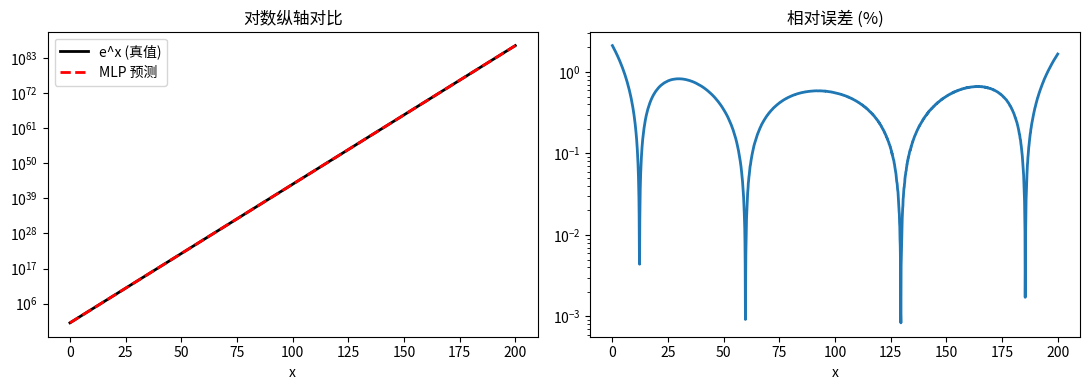

In [13]:
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 下载一个中文字体（只需几秒，只在本 session 有效）
!wget -q -O /tmp/NotoSansCJK.ttf https://github.com/googlefonts/noto-cjk/raw/main/Sans/OTF/SimplifiedChinese/NotoSansCJKsc-Regular.otf

# 注册进 matplotlib
fm.fontManager.addfont('/tmp/NotoSansCJK.ttf')
matplotlib.rcParams['font.family'] = 'Noto Sans CJK SC'
matplotlib.rcParams['axes.unicode_minus'] = False   # 负号也顺便修一下
model.eval()
with torch.no_grad():
    x_test = torch.linspace(0, 200, 2000, dtype=torch.float64)
    u_test = (x_test / 100 - 1).float().unsqueeze(-1).to(device)

    logy_pred = 200.0 * model(u_test).double().cpu()   # 反归一化 → ln y
    y_pred = torch.exp(logy_pred)
    y_true = torch.exp(x_test)

err_log = (logy_pred - x_test).abs()
rel_err = (y_pred - y_true).abs() / y_true

print(f"Maximum absolute error in log space: {err_log.max():.3e}")
print(f"Average relative error in y: {rel_err.mean():.3e} | Maximum {rel_err.max():.3e}")

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(x_test, y_true, 'k-',  lw=2, label='e^x (真值)')
plt.plot(x_test, y_pred, 'r--', lw=2, label='MLP 预测')
plt.yscale('log'); plt.legend(); plt.xlabel('x'); plt.title('对数纵轴对比')

plt.subplot(1, 2, 2)
plt.plot(x_test, rel_err * 100, lw=2)
plt.yscale('log'); plt.xlabel('x'); plt.title('相对误差 (%)')
plt.tight_layout(); plt.show()

In [6]:
print ("演示完成")

演示完成
